In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from neurovision.data import CLASSES, scan_dataset, split_readable, remove_duplicates, load_dataset
from neurovision.preprocessing import make_dataset

RAW_DIR = "../data/raw"
IMG_SIZE = (224, 224)
SEED = 42

I0000 00:00:1791926425.142298    9396 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791926425.143672    9396 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791926425.437673    9396 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791926427.514665    9396 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

### Load the cleaned dataset (deduplicated, shuffled, resized to 224x224)

In [4]:
scan = scan_dataset(RAW_DIR)
ok, corrupted = split_readable(scan["valid"])
files = remove_duplicates(ok)
X, y, paths = load_dataset(files, size=IMG_SIZE, seed=SEED)
print(X.shape, X.dtype, y.shape)

(6726, 224, 224, 3) uint8 (6726,)


### Split into train / validation / test (70/15/15, stratified, before any augmentation)

In [5]:
X_train, X_temp, y_train, y_temp, p_train, p_temp = train_test_split(
    X, y, paths, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test, p_val, p_test = train_test_split(
    X_temp, y_temp, p_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
print(X_train.shape, X_val.shape, X_test.shape)

(4708, 224, 224, 3) (1009, 224, 224, 3) (1009, 224, 224, 3)


### Verify the split: no overlap between sets, class proportions preserved

In [6]:
print(len(set(p_train) & set(p_val)), len(set(p_train) & set(p_test)), len(set(p_val) & set(p_test)))

for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    values, counts = np.unique(labels, return_counts=True)
    print(name, dict(zip(values, np.round(counts / len(labels), 3))))

0 0 0
train {np.str_('glioma'): np.float64(0.241), np.str_('meningioma'): np.float64(0.243), np.str_('notumor'): np.float64(0.257), np.str_('pituitary'): np.float64(0.259)}
val {np.str_('glioma'): np.float64(0.241), np.str_('meningioma'): np.float64(0.243), np.str_('notumor'): np.float64(0.258), np.str_('pituitary'): np.float64(0.259)}
test {np.str_('glioma'): np.float64(0.241), np.str_('meningioma'): np.float64(0.244), np.str_('notumor'): np.float64(0.257), np.str_('pituitary'): np.float64(0.259)}


### Build the tf.data datasets (label encoding, cache, shuffle on train, batch, prefetch)

In [7]:
train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

xb, yb = next(iter(train_ds))
print(xb.shape, xb.dtype, yb.shape)

E0000 00:00:1791926547.881620    9396 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



(32, 224, 224, 3) <dtype: 'uint8'> (32, 4)


### Normalization to [0, 1]: before and after

uint8 0 255
float32 0.0 1.0


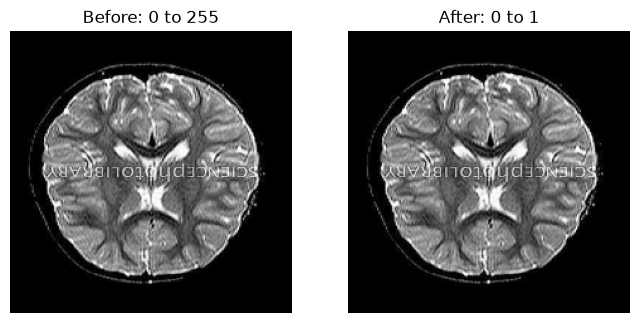

In [8]:
img = X_train[0]
norm = img.astype("float32") / 255.0

print(img.dtype, img.min(), img.max())
print(norm.dtype, norm.min(), norm.max())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title("Before: 0 to 255")
axes[0].axis("off")
axes[1].imshow(norm)
axes[1].set_title("After: 0 to 1")
axes[1].axis("off")
plt.savefig("../reports/normalization.png", dpi=150)
plt.show()

### Data augmentation suited to MRI (training set only)

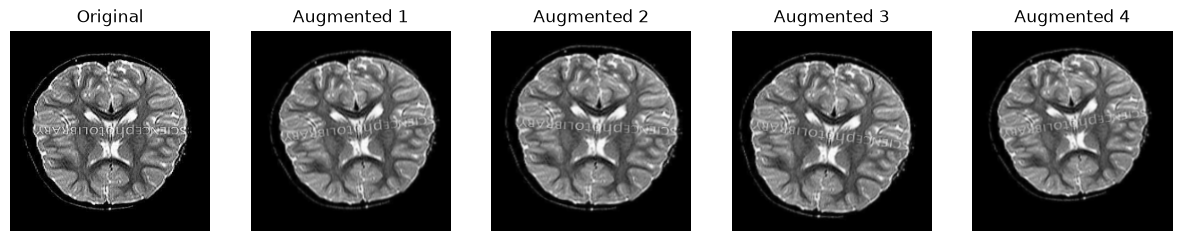

In [9]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
])

sample = tf.convert_to_tensor(norm[None, ...])
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(norm)
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(1, 5):
    augmented = augmentation(sample, training=True)[0].numpy().clip(0, 1)
    axes[i].imshow(augmented)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")
plt.savefig("../reports/augmentation.png", dpi=150)
plt.show()

### Class weights computed on the training set only

In [10]:
y_train_idx = np.array([CLASSES.index(label) for label in y_train])
weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train_idx)
class_weight = dict(enumerate(weights))
print(class_weight)

{0: np.float64(1.0379188712522045), 1: np.float64(1.0288461538461537), 2: np.float64(0.9711221122112211), 3: np.float64(0.9663382594417077)}
